In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import transforms
import torch.optim as optim
import numpy as np
import pandas as pd 
import json

from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
from medmnist import INFO

from tqdm.notebook import tqdm

from medmnist import ChestMNIST, INFO

from torchvision.models import resnet18

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
train_df = ChestMNIST(split="train", download=True)
f"{train_df.labels.shape}, {train_df.labels[:5]}"

'(78468, 14), [[0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]\n [0 0 0 0 0 0 0 0 0 0 0 0 0 0]]'

In [3]:
np.set_printoptions(threshold=np.inf)
print(train_df.labels.sum(axis=1))

[0 0 0 0 0 2 4 1 2 0 0 1 0 1 1 0 0 1 0 0 0 1 0 0 2 2 0 0 2 0 1 1 1 0 0 0 0
 0 2 1 0 0 3 0 3 1 0 1 1 1 0 2 0 0 0 0 2 0 1 2 0 0 4 2 1 0 0 0 0 2 0 1 0 0
 2 1 0 0 4 0 1 1 1 0 3 0 0 0 0 1 0 1 3 0 0 1 0 0 0 0 1 2 1 0 1 0 0 0 3 0 1
 0 0 0 3 0 2 0 3 0 0 2 0 2 1 0 2 0 1 3 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 2
 1 3 0 0 0 0 0 2 2 0 2 0 2 2 0 0 1 0 0 0 1 2 0 1 0 1 1 0 0 1 2 2 0 2 0 1 0
 1 2 0 2 0 1 2 0 0 0 0 1 1 0 1 0 3 0 2 0 0 0 0 1 0 0 2 1 0 0 1 1 0 0 0 4 0
 1 0 1 3 0 0 1 1 1 0 1 0 0 1 1 1 1 2 0 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 0 2 0
 0 2 2 0 0 2 0 2 0 1 1 0 1 0 0 3 0 3 0 2 0 0 0 0 0 0 0 1 1 1 1 2 0 2 0 0 0
 2 0 0 4 0 0 1 1 0 2 0 2 0 0 1 0 3 0 0 2 0 1 0 0 0 0 0 1 1 0 1 3 0 1 0 0 0
 0 2 0 1 1 1 1 0 1 0 0 0 3 3 1 0 0 0 0 2 1 1 0 2 1 0 0 0 2 0 3 1 0 1 2 0 1
 0 0 0 2 3 2 1 2 0 0 0 4 0 0 2 0 0 1 3 2 1 3 0 0 0 1 1 1 1 1 0 2 0 1 1 1 2
 0 2 1 1 0 0 2 1 2 0 0 1 3 1 0 0 0 0 0 0 0 2 0 2 0 0 1 0 0 1 0 2 0 0 0 0 0
 2 0 2 0 1 1 0 1 0 0 0 0 1 0 2 2 0 1 0 2 1 0 0 0 2 2 0 0 2 1 3 2 2 0 0 0 0
 1 1 0 0 0 0 2 2 0 0 0 0 

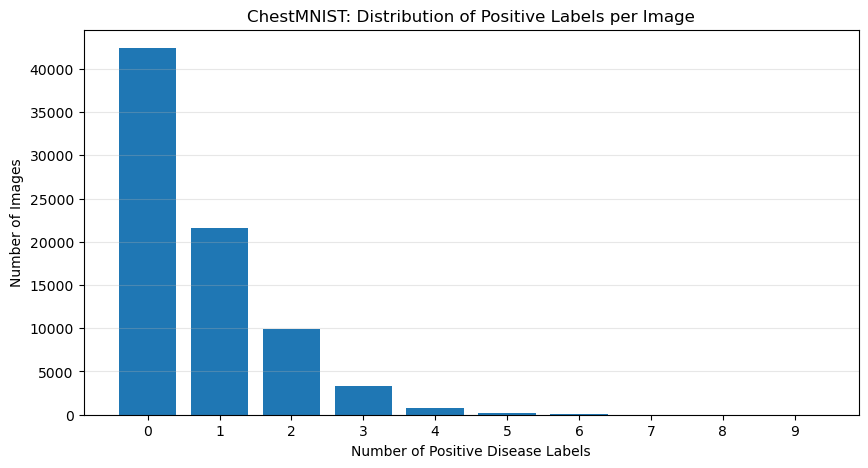

In [4]:
counts = train_df.labels.sum(axis=1)

unique, frequencies = np.unique(counts, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(unique, frequencies)

plt.xlabel("Number of Positive Disease Labels")
plt.ylabel("Number of Images")
plt.title("ChestMNIST: Distribution of Positive Labels per Image")

plt.xticks(unique)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [5]:
unique

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint64)

In [6]:
frequencies

array([42405, 21602,  9970,  3378,   829,   218,    49,    14,     1,
           2])

In [7]:
class_counts = train_df.labels.sum(axis=0)
class_names = list(INFO["chestmnist"]["label"].values())

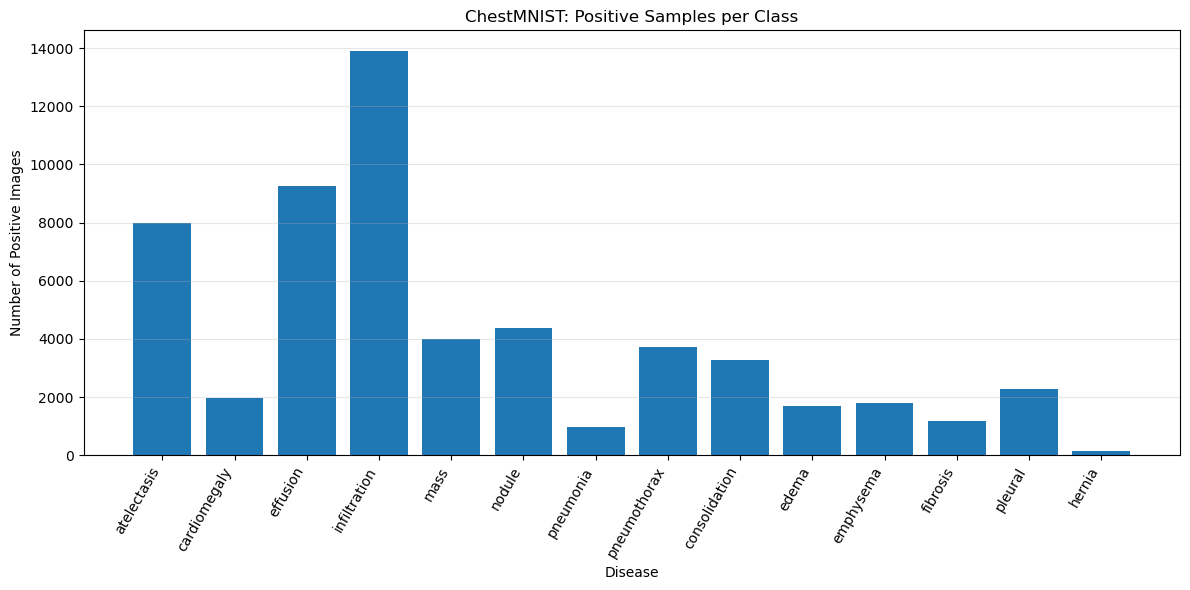

In [8]:
plt.figure(figsize=(12, 6))

plt.bar(class_names, class_counts)

plt.xlabel("Disease")
plt.ylabel("Number of Positive Images")
plt.title("ChestMNIST: Positive Samples per Class")

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = resnet18(weights=None)
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.fc = nn.Linear(model.fc.in_features, 14)

model.load_state_dict(
    torch.load("resnet18_chestMNIST.pth", map_location=device, weights_only=True)
)

model = model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize(mean=[0.5], std=[0.5])])

from torch.utils.data import DataLoader, ConcatDataset

train_data = ChestMNIST(split="train", transform=transform, download=True)
val_data = ChestMNIST(split="val", transform=transform, download=True)
test_data = ChestMNIST(split="test", transform=transform, download=True)

full_data = ConcatDataset([train_data, val_data, test_data])

full_loader = DataLoader(full_data, batch_size=64, shuffle=False)

print(len(full_data))

112120


In [14]:
model.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in full_loader:
        images = images.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits)

        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.numpy())

all_probs = np.concatenate(all_probs, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

In [15]:
f"{all_probs.shape}, {all_labels.shape}"

'(112120, 14), (112120, 14)'

In [16]:
results = []

for i, name in enumerate(class_names):
    positive_probs = all_probs[all_labels[:, i] == 1, i]

    results.append({
        "Class": name,
        "Mean Confidence": positive_probs.mean(),
        "Minimum Confidence": positive_probs.min()
    })

confidence_df = pd.DataFrame(results)
confidence_df

,Class,Mean Confidence,Minimum Confidence
0,atelectasis,0.157118,4.071120e-03
1,cardiomegaly,0.155643,6.123533e-04
2,effusion,0.238775,8.283739e-04
3,infiltration,0.231629,2.170234e-03
4,mass,0.092084,1.869659e-04
5,nodule,0.061346,1.024003e-03
6,pneumonia,0.018525,9.547690e-07
7,pneumothorax,0.135226,1.911435e-03
8,consolidation,0.083965,8.441447e-05
9,edema,0.086619,1.599981e-06


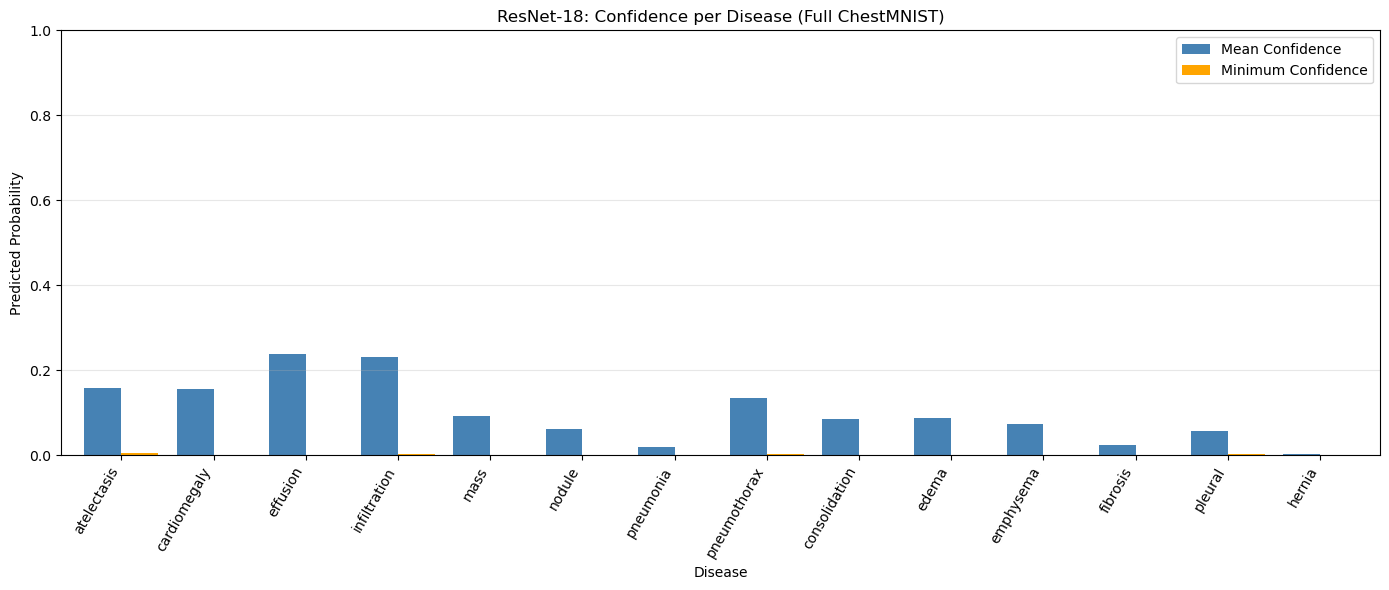

In [17]:
ax = confidence_df.plot(
    x="Class",
    y=["Mean Confidence", "Minimum Confidence"],
    kind="bar",
    figsize=(14, 6),
    width=0.8,
    color=["steelblue", "orange"]
)

plt.title("ResNet-18: Confidence per Disease (Full ChestMNIST)")
plt.xlabel("Disease")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1)

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
results = []

for i, name in enumerate(class_names):
    positive_probs = all_probs[all_labels[:, i] == 1, i]

    results.append({
        "Class": name,
        "Mean": positive_probs.mean(),
        "Median": np.median(positive_probs),
        "10th Percentile": np.percentile(positive_probs, 10)
    })

confidence_df = pd.DataFrame(results)

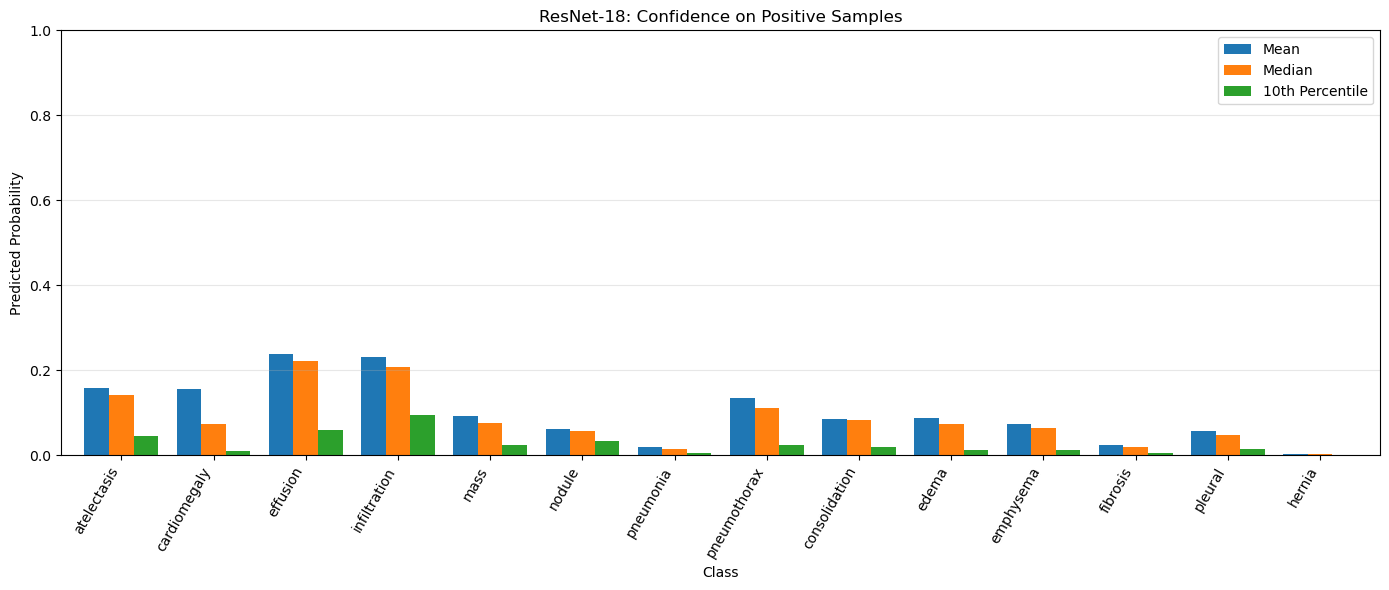

In [19]:
confidence_df.plot(
    x="Class",
    y=["Mean", "Median", "10th Percentile"],
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("ResNet-18: Confidence on Positive Samples")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1)
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
n_train = len(train_data)

train_probs = all_probs[:n_train]
train_labels = all_labels[:n_train]

f"{train_probs.shape}, {train_labels.shape}"

'(78468, 14), (78468, 14)'